# Non-randomness of the clonal embedding

In this notebook we show how to check whether a clonal embedding contains any non-random structure.

The intuition behind the approach is simple. If we randomly shuffle the clonal labels between cells, clones become arbitrary groups of cells, so any structure we see in the resulting embedding appears there just by chance. Repeating this many times gives us a null distribution that we can compare the real data against.

As a measure of how "structured" an embedding is, we use the normalised largest eigenvalue of the embedding matrix: the stronger the clones separate from each other, the more variance is explained by the leading direction. If the clonal embedding reflects real biology, we expect this value to be much larger for the real labels than for the permuted ones.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

Here we are going to work with the dataset from [Ireland et al.](https://www.nature.com/articles/s41586-025-09503-z), which contains the results of lineage tracing in murine SCLC organoids. We load two versions of it: the cell-level object with the gene expression embedding, and the clone-level object with the clone2vec embedding.

In [2]:
adata = c2v.datasets.Ireland_SCLC(embedding_type="gex")
clones = c2v.datasets.Ireland_SCLC(embedding_type="c2v")

using gene expression embedding
using clonal embedding (compositions in adata.X)


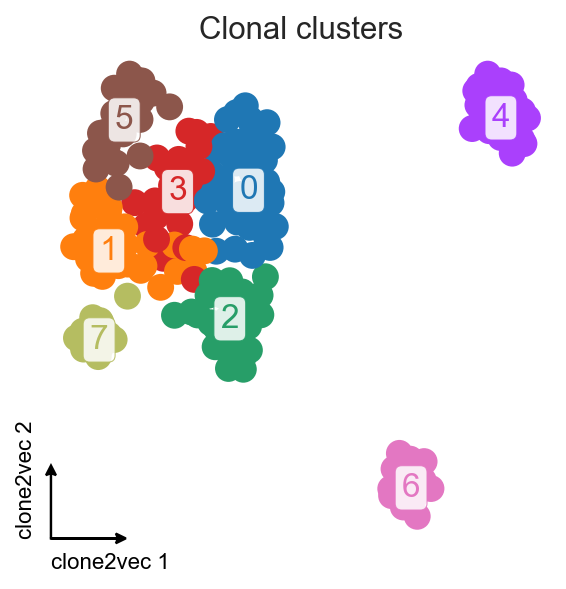

In [3]:
ax = sc.pl.umap(clones, color="leiden", title="Clonal clusters", frameon=False, show=False)

c2v.pl.fancy_legend(ax, textsize=15, center_loc=True)
c2v.pl.embedding_axis(ax, label="clone2vec")

For the further analysis we will keep only the clones from clusters 0, 1, 2, 3, and 5, since they form one big "blob" in the middle of the embedding, and it is not obvious whether they are really separated from each other.

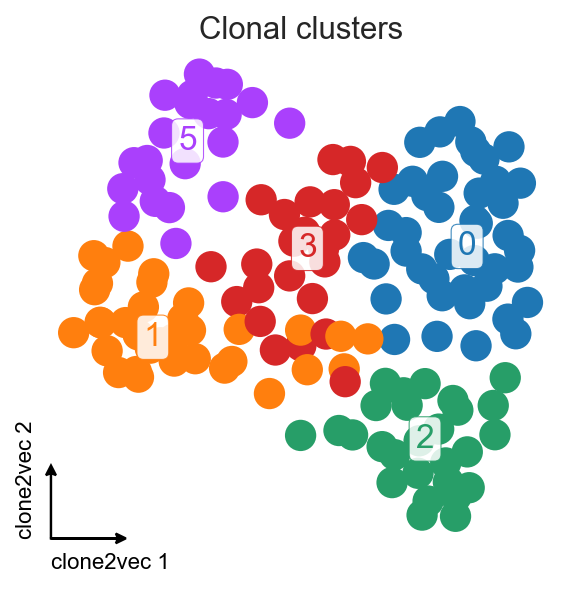

In [4]:
clones = clones[clones.obs.leiden.isin(["1", "3", "5", "0", "2"])].copy()
ax = sc.pl.umap(clones, color="leiden", title="Clonal clusters", frameon=False, show=False)

c2v.pl.fancy_legend(ax, textsize=15, center_loc=True)
c2v.pl.embedding_axis(ax, label="clone2vec")

Now we build the null distribution of the statistic and compare it with the observed value. For every permutation the whole pipeline is re-run (`clonal_nn` followed by `clone2vec`), so the null also accounts for the structure that the embedding procedure itself can produce.

It is important to shuffle the labels within each batch independently: this preserves clone sizes and the batch composition of every clone, so a batch effect — if there is one — is also present in the permuted embeddings and cannot be mistaken for clonal structure.

**Important note**: the statistic is not calculated on the clonal embedding we loaded above (which was built with the multinomial clone2vec model). Instead, the observed embedding is rebuilt with the Poisson model (the default `method="poisson"`), exactly like the permuted ones. Every permutation requires a new clonal embedding, and Poisson embeddings are of comparable quality but are fitted much faster, so it is better to compare Poisson with Poisson.

In [5]:
c2v.tl.spectral_permutation_test(adata, clones, batch_key="Batch")

computing spectral permutation test: 
    embedding permuted clones with 'poisson' flavor
    shuffling 'clone' labels within 'Batch'
    permuting clonal labels (100 permutations): 100%|██████████| 100/100 [05:37<00:00,  3.38s/it]
    finished (0:06:19): added
     .uns['spectral_permutation_test'] eigenvalues test statistics, permutation null distribution, and empirical p-value


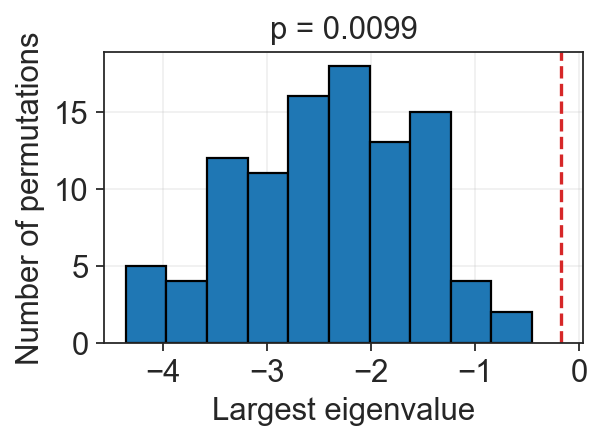

In [6]:
c2v.pl.spectral_permutation_test(clones)

The observed statistic (dashed line) lies far to the right of the whole permutation null, giving an empirical p-value of 0.0099 — the lowest value 100 permutations can give, since it is calculated as `(1 + number of permutations above the observed value) / (number of permutations + 1)`. So, even though these clones look like a single "blob" in the UMAP, their embedding is clearly more structured than expected by chance, and the clusters we see there are worth interpreting.